[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/15-projects/p08-data-analyst-agent-mcp/colab_quickstart.ipynb)

# P8 - Data-analyst agent + MCP server: quick start
An agent answers business questions by calling SQL, pandas, chart and notes tools on a synthetic sales database. The same tools are exposed through an MCP server. CPU runtime, no API key (the default planner is deterministic).

## 1. Get the code
In Colab this clones the course repo. If you are already inside the project folder (running locally), the clone is skipped.

In [1]:
import os, pathlib, subprocess, sys
PROJECT = "p08-data-analyst-agent-mcp"
if pathlib.Path("src").is_dir() and pathlib.Path("README.md").exists():
    print("Project folder found - using the local copy, no clone needed.")
else:
    if not pathlib.Path("AI-Engineer").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/vvvvvivekkk/AI-Engineer.git"], check=True)
    os.chdir(f"AI-Engineer/15-projects/{PROJECT}")
print("working in", os.getcwd())

Project folder found - using the local copy, no clone needed.
working in /home/claude/AI-Engineer/15-projects/p08-data-analyst-agent-mcp


## 2. Install the pinned packages (Colab only)
Colab already has PyTorch with GPU support, so we skip the `torch` line to avoid replacing it. Locally you install with `pip install -r requirements.txt` in a venv.

In [2]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    reqs = [l for l in open("requirements.txt") if l.strip() and not l.startswith(("torch==", "#"))]
    open("/tmp/req.txt", "w").writelines(reqs)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/tmp/req.txt"], check=True)
print("ready")

ready


## 3. Build the database
~11,500 orders for 2025 with three planted anomalies.

In [3]:
!python -m src.make_db

wrote sales.db: 11537 orders, 4 notes in data/notes/


## 4. Ask the agent a question
Each step shows the tool call and a preview of its result.

In [4]:
!python -m src.agent "Which region's revenue fell most last quarter, and why?"

[1] get_schema({})
     -> {"regions": ["region_id INTEGER", "name TEXT"], "products": ["product_id INTEGER", "name TEXT", "category TEXT", "unit_price REAL"], "orders": ["order_id INTEGER", "order_date TEXT", "region_id INTEGE
[2] sql_query({"query": "SELECT r.name AS region, SUM(CASE WHEN substr(o.order_date,6,2) IN ('07','08','09') THEN o.revenue END) AS q3)
     -> {"columns": ["region", "q3", "q4"], "rows": [["East", 136245.5, 148899.25], ["North", 143682.5, 112939.5], ["South", 137075.25, 131679.75], ["West", 146180.75, 135014.25]], "row_count": 4, "truncated"
[3] python_calc({"expression": "df.assign(change_pct=(df.q4 - df.q3) / df.q3 * 100).sort_values('change_pct')[['region', 'change_pct']]")
     -> {"type": "table", "columns": ["region", "change_pct"], "rows": [["North", -21.3965], ["West", -7.6388], ["South", -3.9362], ["East", 9.2875]]}
[4] sql_query({"query": "SELECT p.name AS product, SUM(CASE WHEN substr(o.order_date,6,2) IN ('07','08','09') THEN o.revenue ELSE 0 EN)
  

## 5. Run the 5 test tasks
Checks the exact tool sequence and key facts in each answer.

In [5]:
!python -m src.run_tasks --planner scripted

[PASS] T1 tools=['get_schema', 'sql_query', 'python_calc', 'sql_query', 'search_notes']
       answer: North had the biggest revenue fall from Q3 to Q4 2025 (-21.4%). The largest product drops were Blender Pro, Smart Kettle, Coffee Grinder. Likely reaso
[PASS] T2 tools=['sql_query']
       answer: Top 3 products by 2025 revenue: 1. Ergo Chair ($627,099); 2. Air Purifier ($446,648); 3. Blender Pro ($232,330)


[PASS] T3 tools=['make_chart', 'sql_query']
       answer: Chart saved to outputs/charts/monthly-revenue-2025.png. Highest month 2025-03 ($211,834), lowest 2025-02 ($157,609).
[PASS] T4 tools=['sql_query', 'python_calc', 'search_notes']
       answer: South in 2025-08 stands out: average discount 31% (z-score 6.8, normal is about 4%). Explanation from 2025-08-marketing-south.md: The SUMMER50 promo c
[PASS] T5 tools=['sql_query', 'search_notes']
       answer: Yes: 2025-07-14 in the West region has about 40 more rows than distinct orders. Explanation from 2025-07-it-incident.md: A retry bug in the checkout s

5/5 tasks passed with the scripted planner


## 6. Look at the chart the agent made

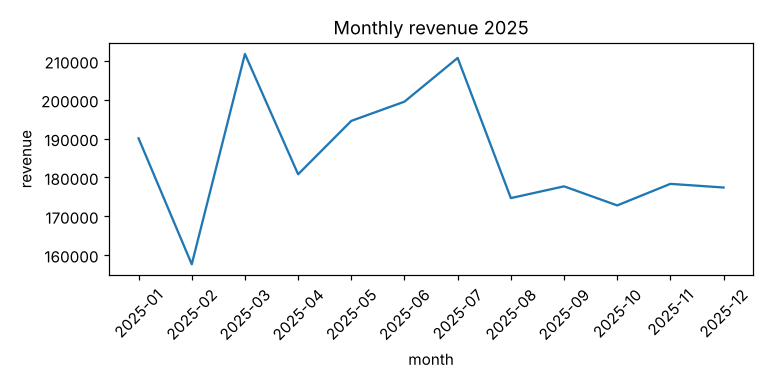

In [6]:
from IPython.display import Image, display
display(Image("outputs/charts/monthly-revenue-2025.png"))

## 7. The MCP server
List the tools and call them through the official MCP SDK - in-process and over stdio (a real subprocess, like Claude Desktop would start).

In [7]:
!python -m src.mcp_check 2>/dev/null

== in-process ==


tools: ['get_schema', 'sql_query', 'python_calc', 'make_chart', 'search_notes']
sql_query -> { "columns": [ "n" ], "rows": [ [ 11537 ] ], "row_count": 1, "truncated": false }
blocked write -> is_error = True | Error executing tool sql_query: Only SELECT (or WITH ... SELECT) queries are allowed.
== stdio subprocess ==


tools: ['get_schema', 'sql_query', 'python_calc', 'make_chart', 'search_notes']
sql_query -> { "columns": [ "n" ], "rows": [ [ 11537 ] ], "row_count": 1, "truncated": false }
blocked write -> is_error = True | Error executing tool sql_query: Only SELECT (or WITH ... SELECT) queries are allowed.


## 8. Run the tests

In [8]:
!python -m pytest -q tests

.......

....

.....

.                                                        [100%]
17 passed in 1.32s


## 9. (Optional) a real LLM planner
In Colab, add `ANTHROPIC_API_KEY` under the key icon (Secrets), then run the next cell. Without a key it explains what is missing.

In [9]:
import os
try:
    from google.colab import userdata
    os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY") or ""
except Exception:
    pass
if os.getenv("ANTHROPIC_API_KEY", "").startswith("sk-"):
    os.environ["LLM_PROVIDER"] = "anthropic"
    !python -m src.run_tasks --planner llm
else:
    print("No ANTHROPIC_API_KEY found - skipping the Claude planner (the scripted planner ran above).")

No ANTHROPIC_API_KEY found - skipping the Claude planner (the scripted planner ran above).
